Relative roughness (ε) = 0.0033333333333333335
First iteration friction factor (calculated with Blasius' formula): 0.009933724094495189
Final friction factor = 0.0431692557119517
Iterations Recap:


,Iteration,Friction Factor (f),Deviation %
0,1,0.054444,NaN
1,2,0.041824,-23.180427
2,3,0.043356,3.663370
3,4,0.043139,-0.500099
4,5,0.043169,0.069688


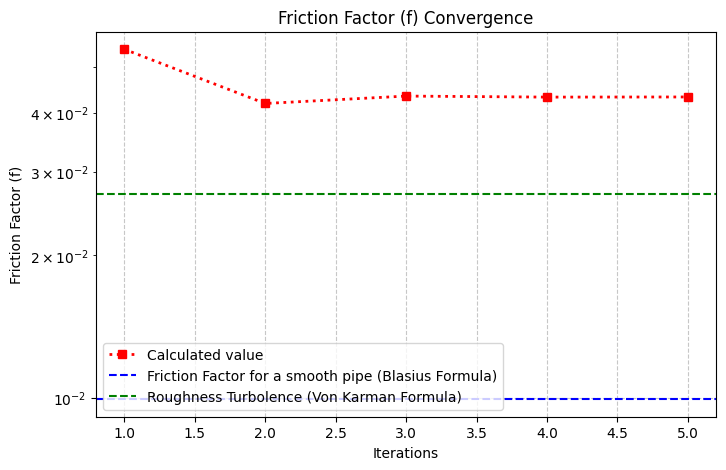

In [16]:
import math
import matplotlib.pyplot as graph
import pandas


#0:dati del problema

Re = float(input("Reynolds Number (Re)     = "))
k  = float(input("Pipe Roughness (k) [m]  = "))
D  = float(input("Pipe Diameter (D) [m]   = "))

#1:calcolo la scabrezza relativa

epsilon = k / D
print(f"Relative roughness (ε) = {epsilon}")

#2:scelgo un valore per il fattore di attrito da cuiu partire; pongo f_old uguale ad f della tubazione liscia, calcolato con l'equazione di Blasius

f_old = 0.079 * Re**(-0.25)
print(f"First iteration friction factor (calculated with Blasius' formula): {f_old}")

#3:preparo le liste di archiviazione dei dati (fattori di attrito e n° iterazioni) che fungeranno da storage dati per il grafico

st_f = []
st_iter = []
iter = 0

#4:imposto il ciclo di iterazioni, che lavora fino a quando lo scarto non è minore dello 0.1%

err = 1

while err > 0.001:
    #progredisco il numero di iterazioni
    iter = iter + 1
    #calcolo la right-hand-side
    RHS = -2 * math.log10(epsilon / 3.7 + 2.51 / (Re * math.sqrt(f_old)))
    #ricavo il nuovo valore di fattore di attrito
    f_new = (1 / RHS) ** 2
    #calcolo l'errore
    err = (abs(f_new - f_old)) / f_old
    #registro i progressi nelle liste
    st_f.append(f_new)
    st_iter.append(iter)
    #pongo il nuovo fattore di attrito della prima iterazione come fattore di attrito di partenza nell'iterazione successiva
    f_old = f_new

print (f"Final friction factor = {f_new}")

#5:imposto una tabella con i dati

#creo un dizionario dati
tab = {
    "Iteration" : st_iter , 
    "Friction Factor (f)" : st_f
}

#trasformo il dizionario in un data frame di pandas
dfp = pandas.DataFrame(tab)

#calcolo l'errore in percentuale
dfp["Deviation %"] = dfp["Friction Factor (f)"].pct_change() * 100

#visualizzo la tabella
print("Iterations Recap:")
display(dfp)

#6:imposto il grafico

graph.figure(figsize = ( 8 , 5))
graph.plot(st_iter , st_f , marker = "s" , linestyle = ":" , color = "red" , linewidth = 2 , label = "Calculated value")
graph.legend()

graph.title("Friction Factor (f) Convergence")
graph.xlabel("Iterations")
graph.ylabel("Friction Factor (f)")
graph.grid(True , linestyle="--" , alpha = 0.7)

#valori di confronto 
f_bls = 0.079 * Re**(-0.25)     #tubo completamente liscio (equazione di blasius)
graph.axhline(y = f_bls , color = "b" , linestyle = "--", label = "Friction Factor for a smooth pipe (Blasius Formula)")

f_vkrm = (1 / (-2 * math.log10(epsilon / 3.7))) ** 2        #velocità talmente alta che comanda solamente la rugosità (formula di von karman)
graph.axhline(y = f_vkrm , color = "g" , linestyle = "--", label = "Roughness Turbolence (Von Karman Formula)")

graph.legend()

graph.yscale("log")

graph.show()


    







